In [1]:
# Secondary analysis & visualization of raw dataset from biometric survey

# Dataset info:
  # Source: Perspectives on facial images, DNA, and other biometrics.
  # Author: J Wagner (2021).
  #   Host: Synapse: https://doi.org/10.7303/SYN25618565.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt       # bar, line plots
import seaborn as sns                 # heatmap plots
from scipy.stats import spearmanr     # correlation test

In [3]:
DIR = "/content/drive/MyDrive/Colab Notebooks/Data"
FILE = f"{DIR}/biometric_data.tsv"

# open stream & check top rows
df = pd.read_csv(FILE, sep="\t")
df.head()

,Start Date,Duration (in seconds),Response ID,In which age group do you belong?,Where in the United States do you currently live?,"Which categories describe you? Select all that apply. Note, you may select more than one group. - Selected Choice","Which categories describe you? Select all that apply. Note, you may select more than one group. - None of these fully describe me. I identify as: - Text",What terms best express how you describe your gender identity? Select all that apply. - Selected Choice,What terms best express how you describe your gender identity? Select all that apply. - None of these describe me. I identify as: - Text,What is the highest grade or year of school you completed?,...,"There are many different types of facial imaging, and the ability to identify an individual from these different types varies. In health research, names and other identifying information are removed from facial imaging to preserve the privacy of the individual. However, reidentification is sometimes possible. Imagine that you are participating in health research involving facial images and facial imaging data. Based on what you know, how concerned are you about your privacy if the following are used and shared as part of that health research? - Geometric surface/Texture map","There are many different types of facial imaging, and the ability to identify an individual from these different types varies. In health research, names and other identifying information are removed from facial imaging to preserve the privacy of the individual. However, reidentification is sometimes possible. Imagine that you are participating in health research involving facial images and facial imaging data. Based on what you know, how concerned are you about your privacy if the following are used and shared as part of that health research? - Imaging data (that is, measurements but not the images themselves)","If you were asked, would you take part in the study?","Regardless of how you answered the previous question, how comfortable would you be with the health study using your medical records, DNA, and facial images? - Medical records and health information","Regardless of how you answered the previous question, how comfortable would you be with the health study using your medical records, DNA, and facial images? - DNA sample and DNA information","Regardless of how you answered the previous question, how comfortable would you be with the health study using your medical records, DNA, and facial images? - Facial images and imaging information","Which of the following statements best reflects the privacy concerns you have for your medical records, DNA samples, facial images, and related information when collected for research purposes?","Now imagine that this study allowed participants to opt-out of sharing certain types of materials and information, even though opting out will hinder research and reduce the health discoveries that could be possible. Which statement best reflects how you would participate or opt-out?",Imagine the organization conducting the study can only fulfill opt-out requests if it charges individuals a one-time fee for each opt-out item. Would you be willing to pay some amount of money for the organization to process your opt-out request?,"Which of the following statements best describes your opinion of how access to research resources (medical records, health data, DNA samples, DNA data, facial images, and facial imaging data) should be managed?"
0,11/24/20 17:55,222,R_12xtYjMVnI2FPmR,56 to 65 years old,Virginia - VA,"Black, African American, or African",NaN,Woman,NaN,Grade 12 or GED (High school graduate),...,Very concerned,Very concerned,Not sure,Somewhat comfortable,Somewhat comfortable,Somewhat comfortable,I am MORE worried about the privacy of my DNA ...,I would opt-out of both DNA information and fa...,Yes,Research resources should be CONTROLLED and ma...
1,11/24/20 17:56,150,R_eV6lVecCwE3Mw9j,26 to 35 years old,Idaho - ID,American In

In [4]:
### PREPARE DATA ###

In [5]:
print(df.shape)

(2010, 83)


In [6]:
# get column headings
for i, col in enumerate(df.columns):
  print(f"{i}: {col}")

0: Start Date
1: Duration (in seconds)
2: Response ID
3: In which age group do you belong?
4: Where in the United States do you currently live?
5: Which categories describe you? Select all that apply. Note, you may select more than one group. - Selected Choice
6: Which categories describe you? Select all that apply. Note, you may select more than one group. - None of these fully describe me. I identify as: - Text
7: What terms best express how you describe your gender identity? Select all that apply. - Selected Choice
8: What terms best express how you describe your gender identity? Select all that apply. - None of these describe me. I identify as: - Text
9: What is the highest grade or year of school you completed?
10: What is your annual household income from all sources?
11: Which most closely describes your political views today?
12: Which most closely describes your political views in general today?
13: Have you ever provided a DNA sample for any reason?
14: Have you ever had medi

In [7]:
# arrays for columns to transfer to new df
cols_id_demo = [
    df.columns[2],   # ID
    df.columns[3],   # age group
    df.columns[4],   # US state
    df.columns[5],   # race
    df.columns[7],   # gender
    df.columns[9],   # education
    df.columns[11]   # political views
]

# experience per type
cols_exp_type = [
    df.columns[15],  # fingerprint
    df.columns[16],  # voice
    df.columns[17],  # facial
    df.columns[18],  # eye
    df.columns[19],  # palm
    df.columns[20]   # dna
]

# comfort by type
cols_acpt_type = [
    df.columns[21],  # fingerprint
    df.columns[22],  # voice
    df.columns[23],  # facial
    df.columns[24],  # eye
    df.columns[25],  # palm
    df.columns[26]   # dna
]

# curr opinion vs 5 years ago & general privacy concerns
cols_priv = [
    df.columns[29]   # privacy concnerns
]

# facial recog trust per organization
cols_trust_org_face = [
    df.columns[30],  # face by ads
    df.columns[31],  # face by tech firms
    df.columns[32],  # face by police
    df.columns[33],  # face by intelligence
    df.columns[34],  # face by med research
    df.columns[35],  # face by healthcare
    df.columns[36],  # face by jobs
    df.columns[37],  # face by edu
    df.columns[38],  # face by retail
    df.columns[39],  # face by state gov
    df.columns[40],  # face by fed gov
    df.columns[41]   # face by foreign
]

# acceptability by applications
cols_acpt_app = [
    df.columns[55],  # surgical patient ID
    df.columns[56],  # hospital security monitoring
    df.columns[57],  # identifying unresponsive patients
    df.columns[58],  # disease diagnosis
    df.columns[59],  # emotion & symptom monitoring
    df.columns[60],  # rx fraud prevention
    df.columns[61],  # staff identity verification
    df.columns[62]   # health research
]

In [8]:
# copy columns from arrays to new df, reordered
df_copy = df[
    cols_id_demo +
    cols_exp_type +
    cols_acpt_type +
    cols_acpt_app +
    cols_trust_org_face +
    cols_priv
].copy()

In [9]:
# check new table
df_copy.head()

,Response ID,In which age group do you belong?,Where in the United States do you currently live?,"Which categories describe you? Select all that apply. Note, you may select more than one group. - Selected Choice",What terms best express how you describe your gender identity? Select all that apply. - Selected Choice,What is the highest grade or year of school you completed?,Which most closely describes your political views today?,"Indicate your experience with each of these six types of biometrics. For example, perhaps you have used biometrics (a fingerprint or face scan) to unlock your smartphone or computer; perhaps you used biometrics (such as a palm scan) to enter a building with restricted access. Please think about all possible contexts. - Fingerprint (digital or ink)","Indicate your experience with each of these six types of biometrics. For example, perhaps you have used biometrics (a fingerprint or face scan) to unlock your smartphone or computer; perhaps you used biometrics (such as a palm scan) to enter a building with restricted access. Please think about all possible contexts. - Voice sample","Indicate your experience with each of these six types of biometrics. For example, perhaps you have used biometrics (a fingerprint or face scan) to unlock your smartphone or computer; perhaps you used biometrics (such as a palm scan) to enter a building with restricted access. Please think about all possible contexts. - Facial image",...,"How much, if at all, do you trust the following groups to use facial recognition technology responsibly? - Intelligence agencies","How much, if at all, do you trust the following groups to use facial recognition technology responsibly? - Health researchers/scientists","How much, if at all, do you trust the following groups to use facial recognition technology responsibly? - Healthcare providers/clinicians","How much, if at all, do you trust the following groups to use facial recognition technology responsibly? - Employers","How much, if at all, do you trust the following groups to use facial recognition technology responsibly? - Schools/Universities","How much, if at all, do you trust the following groups to use facial recognition technology responsibly? - Retailers","How much, if at all, do you trust the following groups to use facial recognition technology responsibly? - State government","How much, if at all, do you trust the following groups to use facial recognition technology responsibly? - Federal government","How much, if at all, do you trust the following groups to use facial recognition technology responsibly? - Foreign government",How concerned are you about the potential misuses of your personal information in general?
0,R_12xtYjMVnI2FPmR,56 to 65 years old,Virginia - VA,"Black, African American, or African",Woman,Grade 12 or GED (High school graduate),Democrat,I am not sure if I have experienced this type ...,"Yes, I have experienced this type of biometric.","Yes, I have experienced this type of biometric.",...,No answer,No answer,No answer,No answer,No answer,No answer,No answer,No answer,No answer,Very concerned
1,R_eV6lVecCwE3Mw9j,26 to 35 years old,Idaho - ID,American Indian or Alaska Native,Woman,College 4 years or more (College graduate),Democrat,"No, I have not experienced this type of biomet...","No, I have not experienced this type of biomet...","Yes, I have experienced this type of biometric.",...,Not at all,Somewhat,Somewhat,Not too much,Not at all,Not too much,Not at all,Not too much,Not at all,Somewhat concerned
2,R_3k6NA5GJpSc17S5,36 to 45 years old,Mississippi - MS,"Black, African American, or African",Man,"1 to 3 years after high school (Some college, ...",Democrat,I am not sure if I have experienced this type ...,I am not sure if I have experienced this type ...,I am not sure if I have experienced this type ...,...,Not at all,No answer,Not at all,Not at all,No answer,Not at all,Not at all,No answer,Not at all,Very concerned
3,R_110JbYI4zYYWHvr,26 to 35 years old,A

In [10]:
for col in cols_trust_org_face:
  print(col)

How much, if at all, do you trust the following groups to use facial recognition technology responsibly? - Advertisers
How much, if at all, do you trust the following groups to use facial recognition technology responsibly? - Technology companies
How much, if at all, do you trust the following groups to use facial recognition technology responsibly? - Law enforcement agencies
How much, if at all, do you trust the following groups to use facial recognition technology responsibly? - Intelligence agencies
How much, if at all, do you trust the following groups to use facial recognition technology responsibly? - Health researchers/scientists
How much, if at all, do you trust the following groups to use facial recognition technology responsibly? - Healthcare providers/clinicians
How much, if at all, do you trust the following groups to use facial recognition technology responsibly? - Employers
How much, if at all, do you trust the following groups to use facial recognition technology respons

In [11]:
# rename columns to usable vars
df_rename = df_copy.copy()

df_rename.columns = [
    # demographics
    "resp_id",
    "demo_age",
    "demo_state",
    "demo_race",
    "demo_gender",
    "demo_edu",
    "demo_pol",

    # experience per modality
    "exp_finger",
    "exp_voice",
    "exp_face",
    "exp_eye",
    "exp_palm",
    "exp_dna",

    # acceptance per modality
    "acpt_type_finger",
    "acpt_type_voice",
    "acpt_type_face",
    "acpt_type_eye",
    "acpt_type_palm",
    "acpt_type_dna",

    # acceptaance per application
    "acpt_app_surgeryid",
    "acpt_app_doorsecurity",
    "acpt_app_patientid",
    "acpt_app_diagnose",
    "acpt_app_emotions",
    "acpt_app_rxfraud",
    "acpt_app_staffid",
    "acpt_app_research",

    # trust in facial recog per org
    "trust_face_ads",
    "trust_face_tech",
    "trust_face_cops",
    "trust_face_intel",
    "trust_face_research",
    "trust_face_healthcare",
    "trust_face_employers",
    "trust_face_edu",
    "trust_face_retailers",
    "trust_face_stategov",
    "trust_face_fedgov",
    "trust_face_foreigngov",

    # privacy concern
    "gen_priv_conc"
]

In [12]:
df_rename.head()

,resp_id,demo_age,demo_state,demo_race,demo_gender,demo_edu,demo_pol,exp_finger,exp_voice,exp_face,...,trust_face_intel,trust_face_research,trust_face_healthcare,trust_face_employers,trust_face_edu,trust_face_retailers,trust_face_stategov,trust_face_fedgov,trust_face_foreigngov,gen_priv_conc
0,R_12xtYjMVnI2FPmR,56 to 65 years old,Virginia - VA,"Black, African American, or African",Woman,Grade 12 or GED (High school graduate),Democrat,I am not sure if I have experienced this type ...,"Yes, I have experienced this type of biometric.","Yes, I have experienced this type of biometric.",...,No answer,No answer,No answer,No answer,No answer,No answer,No answer,No answer,No answer,Very concerned
1,R_eV6lVecCwE3Mw9j,26 to 35 years old,Idaho - ID,American Indian or Alaska Native,Woman,College 4 years or more (College graduate),Democrat,"No, I have not experienced this type of biomet...","No, I have not experienced this type of biomet...","Yes, I have experienced this type of biometric.",...,Not at all,Somewhat,Somewhat,Not too much,Not at all,Not too much,Not at all,Not too much,Not at all,Somewhat concerned
2,R_3k6NA5GJpSc17S5,36 to 45 years old,Mississippi - MS,"Black, African American, or African",Man,"1 to 3 years after high school (Some college, ...",Democrat,I am not sure if I have experienced this type ...,I am not sure if I have experienced this type ...,I am not sure if I have experienced this type ...,...,Not at all,No answer,Not at all,Not at all,No answer,Not at all,Not at all,No answer,Not at all,Very concerned
3,R_110JbYI4zYYWHvr,26 to 35 years old,Arkansas - AR,"Black, African American, or African",Man,Grade 12 or GED (High school graduate),Democrat,"No, I have not experienced this type of biomet...","No, I have not experienced this type of biomet...","Yes, I have experienced this type of biometric.",...,Not at all,Not too much,Somewhat,A great deal,Somewhat,Not too much,Not too much,Not too much,Not at all,Somewhat concerned
4,R_27ygoXcKVCvpYjm,36 to 45 years old,New York - NY,"Black, African American, or African",Man,"1 to 3 years after high school (Some college, ...",Democrat,"Yes, I have experienced this type of biometric.","No, I have not experienced this type of biomet...","Yes, I have experienced this type of biometric.",...,Somewhat,Somewhat,A great deal,A great deal,Somewhat,A great deal,A great deal,Somewhat,A great deal,Very concerned


In [13]:
### CHECK NORMALIZED RESPONSES ###

In [14]:
# count rows with all null answers
empty_rows = df_rename[df_rename.isna().all(axis=1)]
print(f"Number of empty rows = {len(empty_rows)}")

Number of empty rows = 0


In [15]:
# view unique values in experience cols
for col in df_rename.columns[6:12]:
  print(f"\n{col}")
  print(df_rename[col].value_counts(dropna=False))


demo_pol
demo_pol
Democrat                              790
Republican                            503
Independent but leaning Democrat      216
None of these fully describe me.      204
Independent but leaning Republican    200
I prefer not to answer.                97
Name: count, dtype: int64

exp_finger
exp_finger
Yes, I have experienced this type of biometric.                1369
No, I have not experienced this type of biometric.              528
I am not sure if I have experienced this type of biometric.     113
Name: count, dtype: int64

exp_voice
exp_voice
No, I have not experienced this type of biometric.             1258
Yes, I have experienced this type of biometric.                 559
I am not sure if I have experienced this type of biometric.     193
Name: count, dtype: int64

exp_face
exp_face
No, I have not experienced this type of biometric.             1058
Yes, I have experienced this type of biometric.                 767
I am not sure if I have experienced this typ

In [16]:
# check for different storage of nonanswers
for col in df_rename.columns:
  if df_rename[col].dtype == "object":
    print(col.upper() + ":")
    print(df_rename[col].value_counts())
    print()

RESP_ID:
resp_id
R_12xtYjMVnI2FPmR    1
R_eV6lVecCwE3Mw9j    1
R_3k6NA5GJpSc17S5    1
R_110JbYI4zYYWHvr    1
R_27ygoXcKVCvpYjm    1
                    ..
R_2aW7mhELAFxnJ2W    1
R_sp0TXAQEFT7WQDL    1
R_AgN0htMTkeUjjep    1
R_3QG0Ib0X2lWC8sN    1
R_1mRegWfYduDjxdF    1
Name: count, Length: 2010, dtype: int64

DEMO_AGE:
demo_age
26 to 35 years old    364
36 to 45 years old    339
56 to 65 years old    338
46 to 55 years old    319
66 to 75 years old    314
18 to 25 years old    261
76 years and older     75
Name: count, dtype: int64

DEMO_STATE:
demo_state
California - CA              221
New York - NY                190
Florida - FL                 164
Texas - TX                   157
Illinois - IL                 74
Ohio - OH                     71
North Carolina - NC           65
Pennsylvania - PA             64
Michigan - MI                 64
Georgia - GA                  62
New Jersey - NJ               55
Virginia - VA                 55
Colorado - CO                 49
Arizona -

In [17]:
# convert nonanswers to pd.NA (skipped during calculations)
df_rename.replace(["No Answer", "No answer"],
                pd.NA, inplace=True)

In [18]:
# quantify NAs
df_rename.isna().sum().sort_values(ascending=False)

,0
trust_face_foreigngov,100
trust_face_employers,99
trust_face_edu,90
acpt_app_research,85
trust_face_ads,84
acpt_app_rxfraud,83
trust_face_retailers,81
acpt_app_emotions,80
trust_face_intel,79
acpt_app_doorsecurity,79


In [19]:
# check responses equal number respondents except NAs
df_rename.count()

,0
resp_id,2010
demo_age,2010
demo_state,2010
demo_race,2010
demo_gender,2010
demo_edu,2010
demo_pol,2010
exp_finger,2010
exp_voice,2010
exp_face,2010


In [20]:
### CONVERT RESPONSES TO ORDINAL INTS ###

In [21]:
# check experience responses
exp_resp = df_rename["exp_finger"].unique()

# check acceptance per modality responses
acpt_type_resp = df_rename["acpt_type_finger"].unique()

# check acceptance per application responses
acpt_app_resp = df_rename["acpt_app_surgeryid"].unique()

# check trust in FR per org repsonses
trust_resp = df_rename["trust_face_ads"].unique()

# check privacy concern responses
priv_resp = df_rename["gen_priv_conc"].unique()

print(exp_resp)
print(acpt_type_resp)
print(acpt_app_resp)
print(trust_resp)
print(priv_resp)

['I am not sure if I have experienced this type of biometric.'
 'No, I have not experienced this type of biometric.'
 'Yes, I have experienced this type of biometric.']
[6 1 2 5 3 4]
[<NA> 'Unacceptable' 'Not Sure' 'Acceptable']
[<NA> 'Not too much' 'Not at all' 'Somewhat' 'A great deal']
['Very concerned' 'Somewhat concerned' 'Not very concerned'
 'Not concerned at all' 'Don’t know']


In [22]:
# convert qualitative responses to ordinal integers
exp_map = {
    "No, I have not experienced this type of biometric.": 1,
    "I am not sure if I have experienced this type of biometric.": 2,
    "Yes, I have experienced this type of biometric.": 3
}

acpt_app_map = {
    "Unacceptable": 1,
    "Not Sure": 2,
    "Acceptable": 3
}

trust_map = {
    "Not at all": 1,
    "Not too much": 2,
    "Somewhat": 3,
    "A great deal": 4
}

priv_map = {
    "Very concerned": 5,
    "Somewhat concerned": 4,
    "Don’t know": 3,
    "Not very concerned": 2,
    "Not concerned at all": 1
}

In [23]:
# copy to new df
df_ints = df_rename.copy()
df_ints.head()

,resp_id,demo_age,demo_state,demo_race,demo_gender,demo_edu,demo_pol,exp_finger,exp_voice,exp_face,...,trust_face_intel,trust_face_research,trust_face_healthcare,trust_face_employers,trust_face_edu,trust_face_retailers,trust_face_stategov,trust_face_fedgov,trust_face_foreigngov,gen_priv_conc
0,R_12xtYjMVnI2FPmR,56 to 65 years old,Virginia - VA,"Black, African American, or African",Woman,Grade 12 or GED (High school graduate),Democrat,I am not sure if I have experienced this type ...,"Yes, I have experienced this type of biometric.","Yes, I have experienced this type of biometric.",...,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,Very concerned
1,R_eV6lVecCwE3Mw9j,26 to 35 years old,Idaho - ID,American Indian or Alaska Native,Woman,College 4 years or more (College graduate),Democrat,"No, I have not experienced this type of biomet...","No, I have not experienced this type of biomet...","Yes, I have experienced this type of biometric.",...,Not at all,Somewhat,Somewhat,Not too much,Not at all,Not too much,Not at all,Not too much,Not at all,Somewhat concerned
2,R_3k6NA5GJpSc17S5,36 to 45 years old,Mississippi - MS,"Black, African American, or African",Man,"1 to 3 years after high school (Some college, ...",Democrat,I am not sure if I have experienced this type ...,I am not sure if I have experienced this type ...,I am not sure if I have experienced this type ...,...,Not at all,<NA>,Not at all,Not at all,<NA>,Not at all,Not at all,<NA>,Not at all,Very concerned
3,R_110JbYI4zYYWHvr,26 to 35 years old,Arkansas - AR,"Black, African American, or African",Man,Grade 12 or GED (High school graduate),Democrat,"No, I have not experienced this type of biomet...","No, I have not experienced this type of biomet...","Yes, I have experienced this type of biometric.",...,Not at all,Not too much,Somewhat,A great deal,Somewhat,Not too much,Not too much,Not too much,Not at all,Somewhat concerned
4,R_27ygoXcKVCvpYjm,36 to 45 years old,New York - NY,"Black, African American, or African",Man,"1 to 3 years after high school (Some college, ...",Democrat,"Yes, I have experienced this type of biometric.","No, I have not experienced this type of biomet...","Yes, I have experienced this type of biometric.",...,Somewhat,Somewhat,A great deal,A great deal,Somewhat,A great deal,A great deal,Somewhat,A great deal,Very concerned


In [24]:
# apply exp conversion
exp_cols = [col for col in df_ints.columns if col.startswith("exp_")]
for col in exp_cols:
    df_ints[col] = df_ints[col].map(exp_map).astype("Int64")

# reverse acpt by modality responses such that 1=least acptbl, 6=most
acpt_type_cols = [col for col in df_ints.columns if col.startswith("acpt_type_")]
for col in acpt_type_cols:
  df_ints[col] = 7 - df_ints[col]

# apply acpt by app conversion
acpt_app_cols = [col for col in df_ints.columns if col.startswith("acpt_app_")]
for col in acpt_app_cols:
  df_ints[col] = df_ints[col].map(acpt_app_map).astype("Int64")

# apply trust in FR by org conversion
trust_cols = [col for col in df_ints.columns if col.startswith("trust_face_")]
for col in trust_cols:
  df_ints[col] = df_ints[col].map(trust_map).astype("Int64")

# apply privacy concern conversion
df_ints["gen_priv_conc"] = (
    df_ints["gen_priv_conc"]
    .map(priv_map)
    .astype("Int64")
)

In [25]:
# veryify mappings
print(df_ints[exp_cols].isna().sum())
print(df_ints[acpt_app_cols].isna().sum())
print(df_ints[trust_cols].isna().sum())
print(df_ints["gen_priv_conc"].isna().sum())

exp_finger    0
exp_voice     0
exp_face      0
exp_eye       0
exp_palm      0
exp_dna       0
dtype: int64
acpt_app_surgeryid       74
acpt_app_doorsecurity    79
acpt_app_patientid       71
acpt_app_diagnose        71
acpt_app_emotions        80
acpt_app_rxfraud         83
acpt_app_staffid         66
acpt_app_research        85
dtype: int64
trust_face_ads            84
trust_face_tech           77
trust_face_cops           67
trust_face_intel          79
trust_face_research       74
trust_face_healthcare     68
trust_face_employers      99
trust_face_edu            90
trust_face_retailers      81
trust_face_stategov       73
trust_face_fedgov         64
trust_face_foreigngov    100
dtype: int64
0


In [26]:
df_rename.head()

,resp_id,demo_age,demo_state,demo_race,demo_gender,demo_edu,demo_pol,exp_finger,exp_voice,exp_face,...,trust_face_intel,trust_face_research,trust_face_healthcare,trust_face_employers,trust_face_edu,trust_face_retailers,trust_face_stategov,trust_face_fedgov,trust_face_foreigngov,gen_priv_conc
0,R_12xtYjMVnI2FPmR,56 to 65 years old,Virginia - VA,"Black, African American, or African",Woman,Grade 12 or GED (High school graduate),Democrat,I am not sure if I have experienced this type ...,"Yes, I have experienced this type of biometric.","Yes, I have experienced this type of biometric.",...,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,Very concerned
1,R_eV6lVecCwE3Mw9j,26 to 35 years old,Idaho - ID,American Indian or Alaska Native,Woman,College 4 years or more (College graduate),Democrat,"No, I have not experienced this type of biomet...","No, I have not experienced this type of biomet...","Yes, I have experienced this type of biometric.",...,Not at all,Somewhat,Somewhat,Not too much,Not at all,Not too much,Not at all,Not too much,Not at all,Somewhat concerned
2,R_3k6NA5GJpSc17S5,36 to 45 years old,Mississippi - MS,"Black, African American, or African",Man,"1 to 3 years after high school (Some college, ...",Democrat,I am not sure if I have experienced this type ...,I am not sure if I have experienced this type ...,I am not sure if I have experienced this type ...,...,Not at all,<NA>,Not at all,Not at all,<NA>,Not at all,Not at all,<NA>,Not at all,Very concerned
3,R_110JbYI4zYYWHvr,26 to 35 years old,Arkansas - AR,"Black, African American, or African",Man,Grade 12 or GED (High school graduate),Democrat,"No, I have not experienced this type of biomet...","No, I have not experienced this type of biomet...","Yes, I have experienced this type of biometric.",...,Not at all,Not too much,Somewhat,A great deal,Somewhat,Not too much,Not too much,Not too much,Not at all,Somewhat concerned
4,R_27ygoXcKVCvpYjm,36 to 45 years old,New York - NY,"Black, African American, or African",Man,"1 to 3 years after high school (Some college, ...",Democrat,"Yes, I have experienced this type of biometric.","No, I have not experienced this type of biomet...","Yes, I have experienced this type of biometric.",...,Somewhat,Somewhat,A great deal,A great deal,Somewhat,A great deal,A great deal,Somewhat,A great deal,Very concerned


In [27]:
### MEAN CALCULATIONS ###

In [28]:
# mean overall experience per modality (1-3), rounded 3 places
exp_names = {
    "exp_finger": "Fingerprint",
    "exp_voice": "Voice Recog.",
    "exp_face": "Facial Recog.",
    "exp_eye": "Iris/Retina",
    "exp_palm": "Palm Geometry",
    "exp_dna": "DNA"
}

mean_exp = (
    df_ints[exp_cols].mean().round(3)
    .rename(index=exp_names))

tbl_exp = mean_exp.reset_index()
tbl_exp.columns = ["MODALITY", "| MEAN EXPERIENCE (1-3)"]
display(tbl_exp)

,MODALITY,| MEAN EXPERIENCE (1-3)
0,Fingerprint,2.418
1,Voice Recog.,1.652
2,Facial Recog.,1.855
3,Iris/Retina,1.676
4,Palm Geometry,1.579
5,DNA,1.789


In [29]:
# mean overall acceptance per modality (1-6), rounded 3 places
acpt_type_names = {
    "acpt_type_finger": "Fingerprint",
    "acpt_type_voice": "Voice Recog.",
    "acpt_type_face": "Facial Recog.",
    "acpt_type_eye": "Iris/Retina",
    "acpt_type_palm": "Palm Geometry",
    "acpt_type_dna": "DNA"
}

mean_acpt_type = (
    df_ints[acpt_type_cols].mean().round(3)
    .rename(index=acpt_type_names)
)

tbl_acpt_type = mean_acpt_type.reset_index()
tbl_acpt_type.columns = ["MODALITY", "| MEAN ACCEPTANCE (1-6)"]
display(tbl_acpt_type)

,MODALITY,| MEAN ACCEPTANCE (1-6)
0,Fingerprint,4.474
1,Voice Recog.,3.560
2,Facial Recog.,3.390
3,Iris/Retina,3.263
4,Palm Geometry,3.527
5,DNA,2.786


In [30]:
# mean overall acceptance per applications (1-3), rounded 3 places
acpt_app_names = {
    "acpt_app_surgeryid": "Patient ID",
    "acpt_app_doorsecurity": "Building Security",
    "acpt_app_patientid": "Misc Medical ID",
    "acpt_app_diagnose": "Diagnosing",
    "acpt_app_emotions": "Emotion Tracking",
    "acpt_app_rxfraud": "Rx Customer ID",
    "acpt_app_staffid": "Staff ID Verify",
    "acpt_app_research": "Bio Research"
}

mean_acpt_app = (
    df_ints[acpt_app_cols].mean().round(2)
    .rename(index=acpt_app_names)
)

tbl_acpt_app = mean_acpt_app.reset_index()
tbl_acpt_app.columns = ["APPLICATION", "| MEAN ACCEPTANCE (1-3)"]
display(tbl_acpt_app)

,APPLICATION,| MEAN ACCEPTANCE (1-3)
0,Patient ID,2.51
1,Building Security,2.41
2,Misc Medical ID,2.5
3,Diagnosing,2.45
4,Emotion Tracking,2.27
5,Rx Customer ID,2.31
6,Staff ID Verify,2.49
7,Bio Research,2.26


In [31]:
# mean overall trust in FR per organization (1-4), rounded 3 places
trust_names = {
    "trust_face_ads": "Advertising Firms",
    "trust_face_tech": "Technology Firms",
    "trust_face_cops": "Policing Agencies",
    "trust_face_intel": "Intelligence Agencies",
    "trust_face_research": "Research Institutes",
    "trust_face_healthcare": "Healthcare Offices",
    "trust_face_employers": "Employers",
    "trust_face_edu": "Public/Private Education",
    "trust_face_retailers": "Retail Companies",
    "trust_face_stategov": "U.S. State Govs",
    "trust_face_fedgov": "U.S. Federal Gov",
    "trust_face_foreigngov": "Foreign Govts",
}

mean_trust = (
    df_ints[trust_cols].mean().round(3)
    .rename(index=trust_names)
)

tbl_trust = mean_trust.reset_index()
tbl_trust.columns = ["FACIAL RECOG BY ORGANIZATION", "| MEAN TRUST (1-4)"]
display(tbl_trust)


,FACIAL RECOG BY ORGANIZATION,| MEAN TRUST (1-4)
0,Advertising Firms,2.152
1,Technology Firms,2.367
2,Policing Agencies,2.681
3,Intelligence Agencies,2.581
4,Research Institutes,2.866
5,Healthcare Offices,2.863
6,Employers,2.47
7,Public/Private Education,2.502
8,Retail Companies,2.151
9,U.S. State Govs,2.41


In [32]:
# mean privacy across respondents
mean_priv = df_ints["gen_priv_conc"].mean()
print(f"Mean privacy concern across respondents ={mean_priv: .3f} / 5 (5 = most concerned)")

Mean privacy concern across respondents = 4.194 / 5 (5 = most concerned)


In [33]:
# mean accepterance per modality grouped-by age range (1-3), rounded 3 places
mean_acpt_byage = (
    df_ints.groupby("demo_age")[acpt_type_cols]
    .mean().round(3)
)
mean_acpt_byage = mean_acpt_byage.rename(columns=acpt_type_names)
display(mean_acpt_byage)

,Fingerprint,Voice Recog.,Facial Recog.,Iris/Retina,Palm Geometry,DNA
demo_age,,,,,,
18 to 25 years old,4.169,3.747,3.360,3.284,3.471,2.969
26 to 35 years old,4.283,3.459,3.464,3.190,3.445,3.159
36 to 45 years old,4.375,3.555,3.472,3.298,3.590,2.711
46 to 55 years old,4.483,3.724,3.467,3.179,3.530,2.618
56 to 65 years old,4.692,3.467,3.275,3.272,3.716,2.577
66 to 75 years old,4.758,3.481,3.325,3.350,3.417,2.669
76 years and older,4.707,3.467,3.227,3.347,3.427,2.827


In [34]:
# mean acceptance per modality grouped-by race
mean_acpt_byrace = (
    df_ints.groupby("demo_race")[acpt_type_cols]
    .mean().round(3)
)
mean_acpt_byrace = mean_acpt_byrace.rename(columns=acpt_type_names)
display(mean_acpt_byrace)

,Fingerprint,Voice Recog.,Facial Recog.,Iris/Retina,Palm Geometry,DNA
demo_race,,,,,,
American Indian or Alaska Native,4.077,3.077,3.256,3.231,3.821,3.538
"American Indian or Alaska Native,Asian",3.500,3.500,4.000,4.000,2.500,3.500
"American Indian or Alaska Native,Asian,Black, African American, or African,Hispanic, Latino, or Spanish,White",4.000,5.000,3.000,2.000,6.000,1.000
"American Indian or Alaska Native,Asian,Hispanic, Latino, or Spanish,Middle Eastern or North African,White,None of these fully describe me. I identify as:",6.000,5.000,3.000,2.000,4.000,1.000
"American Indian or Alaska Native,Asian,White",5.000,4.000,6.000,3.000,2.000,1.000
"American Indian or Alaska Native,Black, African American, or African",3.667,3.333,3.667,2.667,3.667,4.000
"American Indian or Alaska Native,Black, African American, or African,Hispanic, Latino, or Spanish,White",4.000,3.333,4.000,2.667,2.000,5.000
"American Indian or Alaska Native,Black, African American, or African,White",4.000,5.000,3.000,2.000,1.000,6.000
"American Indian or Alaska Native,Hispanic, Latino, or Spanish",4.500,3.500,3.500,3.750,3.000,2.750


In [35]:
# mean acceptance per modality grouped-by gender
mean_acpt_bygender = (
    df_ints.groupby("demo_gender")[acpt_type_cols]
    .mean().round(3)
)
mean_acpt_bygender = mean_acpt_bygender.rename(columns=acpt_type_names)
display(mean_acpt_bygender)

,Fingerprint,Voice Recog.,Facial Recog.,Iris/Retina,Palm Geometry,DNA
demo_gender,,,,,,
I prefer not to answer.,3.750,3.417,3.833,3.000,3.667,3.333
Man,4.369,3.535,3.435,3.299,3.520,2.843
"Man,Non-binary",4.000,1.000,6.000,3.000,2.000,5.000
"Man,None of these describe me. I identify as:",6.000,3.000,4.000,5.000,1.000,2.000
"Man,Transgender",4.000,1.000,5.000,6.000,2.000,3.000
"Man,Woman",4.000,2.500,2.500,5.000,1.500,5.500
"Man,Woman,Non-binary,Transgender,None of these describe me. I identify as:",6.000,4.000,1.000,5.000,2.000,3.000
Non-binary,4.833,3.750,2.917,2.750,3.917,2.833
None of these describe me. I identify as:,4.667,5.000,2.333,3.333,2.333,3.333


In [36]:
# mean acceptance per modality grouped-by edu level
# reindex labels
edu_labels = {
    "Never attended school or only attended kindergarten": "Never attended",
    "Grades 1 through 4 (Primary school)": "Primary school",
    "Grades 5 through 8 (Middle school)": "Middle school",
    "Grades 9 through 11 (Some high school)": "Some HS",
    "Grade 12 or GED (High school graduate)": "HS Diploma/GED",
    "1 to 3 years after high school (Some college, Associate’s degree, or technical school)": "Some college/Cert.",
    "College 4 years or more (College graduate)": "Undergraduate",
    "Advanced degree (Master’s, Doctorate, etc.)": "Advanced",
    "I prefer not to answer.": "No Answer"
}

mean_acpt_byedu = (
    df_ints.groupby("demo_edu")[acpt_type_cols]
    .mean().round(3)
)
mean_acpt_byedu = mean_acpt_byedu.rename(columns=acpt_type_names, index=edu_labels)
display(mean_acpt_byedu)

,Fingerprint,Voice Recog.,Facial Recog.,Iris/Retina,Palm Geometry,DNA
demo_edu,,,,,,
Some college/Cert.,4.609,3.542,3.382,3.239,3.614,2.613
Advanced,4.492,3.436,3.333,3.289,3.542,2.908
Undergraduate,4.557,3.687,3.413,3.269,3.527,2.547
HS Diploma/GED,4.323,3.516,3.457,3.273,3.423,3.009
Primary school,3.533,4.067,3.067,3.000,4.000,3.333
Middle school,3.765,3.353,3.176,3.647,3.706,3.353
Some HS,4.357,3.304,3.179,3.054,3.464,3.643
No Answer,3.920,3.760,3.240,3.600,3.160,3.320
Never attended,3.706,4.471,3.882,3.176,3.059,2.706


In [37]:
# mean acceptance per modality grouped-by political affiliation
mean_acpt_bypol = (
    df_ints.groupby("demo_pol")[acpt_type_cols]
    .mean().round(3)
)
mean_acpt_bypol = mean_acpt_bypol.rename(columns=acpt_type_names)
display(mean_acpt_bypol)

,Fingerprint,Voice Recog.,Facial Recog.,Iris/Retina,Palm Geometry,DNA
demo_pol,,,,,,
Democrat,4.339,3.527,3.467,3.282,3.480,2.905
I prefer not to answer.,4.433,3.763,3.485,3.103,3.340,2.876
Independent but leaning Democrat,4.556,3.759,3.222,3.269,3.574,2.620
Independent but leaning Republican,4.645,3.490,3.360,3.335,3.570,2.600
None of these fully describe me.,4.627,3.466,3.402,3.157,3.637,2.711
Republican,4.529,3.553,3.330,3.276,3.555,2.757


In [38]:
# mean acceptance per modality grouped-by state regions
region_map = {
    # NE (northeast region)
    "Connecticut - CT": "NE",
    "Maine - ME": "NE",
    "Massachusetts - MA": "NE",
    "New Hampshire - NH": "NE",
    "Rhode Island - RI": "NE",
    "New Jersey - NJ": "NE",
    "New York - NY": "NE",
    "Pennsylvania - PA": "NE",
    "Vermont - VT": "NE",

    # MW (midwest region)
    "Illinois - IL": "MW",
    "Indiana - IN": "MW",
    "Iowa - IA": "MW",
    "Kansas - KS": "MW",
    "Michigan - MI": "MW",
    "Minnesota - MN": "MW",
    "Missouri - MO": "MW",
    "Nebraska - NE": "MW",
    "North Dakota - ND": "MW",
    "Ohio - OH": "MW",
    "South Dakota - SD": "MW",
    "Wisconsin - WI": "MW",

    # S (south region)
    "Alabama - AL": "S",
    "Arkansas - AR": "S",
    "Delaware - DE": "NE",
    "Florida - FL": "S",
    "Georgia - GA": "S",
    "Kentucky - KY": "S",
    "Louisiana - LA": "S",
    "Maryland - MD": "NE",
    "Mississippi - MS": "S",
    "North Carolina - NC": "S",
    "Oklahoma - OK": "S",
    "South Carolina - SC": "S",
    "Tennessee - TN": "S",
    "Texas - TX": "S",
    "Virginia - VA": "S",
    "West Virginia - WV": "S",

    # W (west region)
    "Alaska - AK": "W",
    "Arizona - AZ": "W",
    "California - CA": "W",
    "Colorado - CO": "W",
    "Hawaii - HI": "W",
    "Idaho - ID": "W",
    "Montana - MT": "W",
    "Nevada - NV": "W",
    "New Mexico - NM": "W",
    "Oregon - OR": "W",
    "Utah - UT": "W",
    "Washington - WA": "W",
    "Wyoming - WY": "W",

    # convert DC & territories to NAs due microsamples
    "District of Columbia - DC": pd.NA,
    "Guam - GU": pd.NA,
    "Puerto Rico - PR": pd.NA
}

# map states to regions
df_ints["demo_region"] = (df_ints["demo_state"].map(region_map))

# verify 50 states in df & dict (gu & pr excluded)
num_df = len(set(df_ints["demo_state"].dropna().unique()))-3
num_dict = len(region_map)-3

print(f"Num states in data: {num_df} / 50   *excluding DC, GU, PR")
print(f"Num states in dict: {num_dict} / 50   *excluding DC, GU, PR")

Num states in data: 50 / 50   *excluding DC, GU, PR
Num states in dict: 50 / 50   *excluding DC, GU, PR


In [39]:
mean_acpt_byregion = (
    df_ints.groupby("demo_region")[acpt_type_cols]
    .mean().round(3)
)
mean_acpt_byregion = mean_acpt_byregion.rename(columns=acpt_type_names)
display(mean_acpt_byregion)

,Fingerprint,Voice Recog.,Facial Recog.,Iris/Retina,Palm Geometry,DNA
demo_region,,,,,,
MW,4.509,3.669,3.318,3.226,3.531,2.747
NE,4.392,3.608,3.387,3.310,3.433,2.869
S,4.508,3.449,3.385,3.252,3.516,2.890
W,4.486,3.601,3.451,3.271,3.614,2.576


In [40]:
### VISUALIZATIONS ###

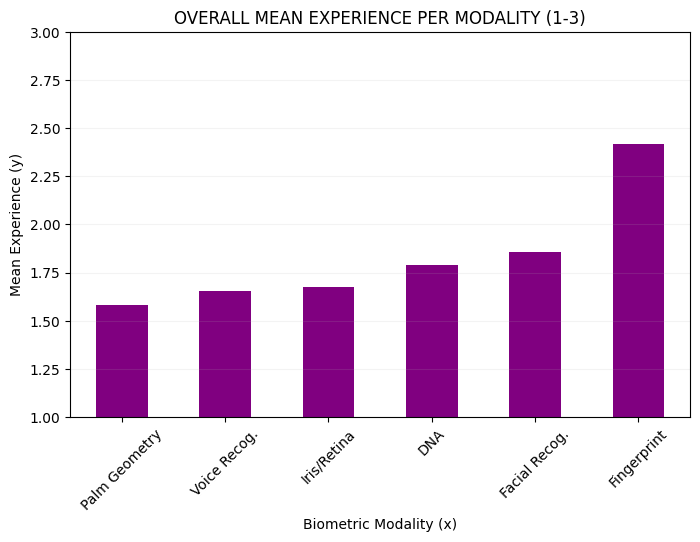

In [41]:
# mean exp per modality bar plot
mean_exp.sort_values().plot.bar(
    figsize=(8,5),
    color="purple"
)

plt.xticks(rotation=45)
plt.ylim(1.0, 3.0)
plt.grid(axis="y", alpha=0.15)

plt.xlabel("Biometric Modality (x)")
plt.ylabel("Mean Experience (y)")
plt.title("OVERALL MEAN EXPERIENCE PER MODALITY (1-3)")

plt.show()

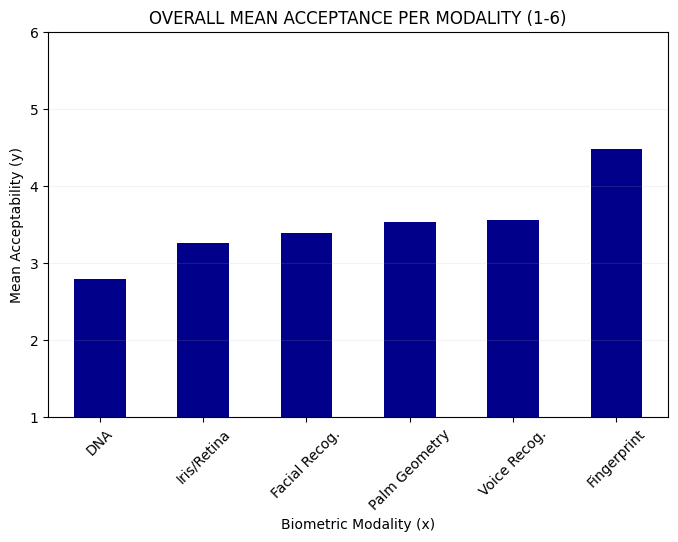

In [42]:
# mean overall acpt per modality bar plot
mean_acpt_type.sort_values().plot.bar(
    figsize=(8,5),
    color="darkblue"
)

plt.xticks(rotation=45)
plt.ylim(1.0, 6.0)
plt.grid(axis="y", alpha=0.15)

plt.xlabel("Biometric Modality (x)")
plt.ylabel("Mean Acceptability (y)")
plt.title("OVERALL MEAN ACCEPTANCE PER MODALITY (1-6)")

plt.show()

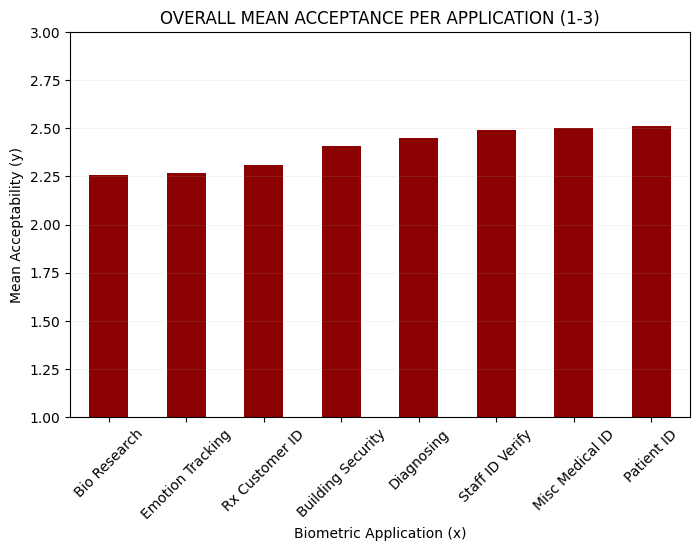

In [43]:
# mean overall acpt per app bar plot
mean_acpt_app.sort_values().plot.bar(
    figsize=(8,5),
    color="darkred"
)

plt.xticks(rotation=45)
plt.ylim(1.0, 3.0)
plt.grid(axis="y", alpha=0.15)

plt.xlabel("Biometric Application (x)")
plt.ylabel("Mean Acceptability (y)")
plt.title("OVERALL MEAN ACCEPTANCE PER APPLICATION (1-3)")

plt.show()

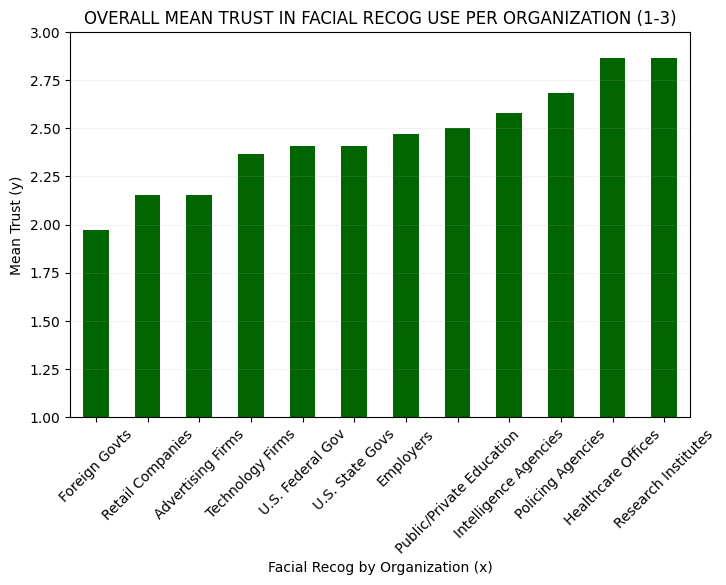

In [44]:
# mean trust in fr per org bar plot
mean_trust.sort_values().plot.bar(
    figsize=(8,5),
    color="darkgreen"
)

plt.xticks(rotation=45)
plt.ylim(1.0, 3.0)

plt.xlabel("Facial Recog by Organization (x)")
plt.ylabel("Mean Trust (y)")
plt.title("OVERALL MEAN TRUST IN FACIAL RECOG USE PER ORGANIZATION (1-3)")

plt.grid(axis="y", alpha=0.15)
plt.show()

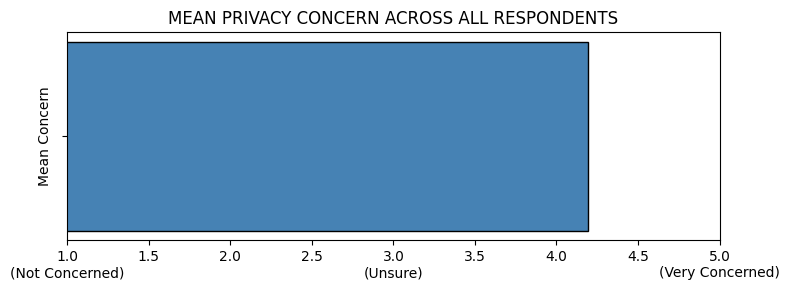

In [45]:
# mean privacy across respondents barh plot
plt.figure(figsize=(8, 3))

plt.barh(
    [""],
    [mean_priv],
    color="steelblue",
    edgecolor="black"
)

plt.xlim(1, 5)
plt.xticks(
    [1.0, 1.5, 2.0, 2.5, 3.0, 3.5, 4.0, 4.5, 5.0],
    ["1.0\n(Not Concerned)", "1.5", "2.0", "2.5", "3.0\n(Unsure)", "3.5", "4.0", "4.5", "5.0\n(Very Concerned)"]
)

plt.ylabel("Mean Concern")
plt.title("MEAN PRIVACY CONCERN ACROSS ALL RESPONDENTS")

plt.tight_layout()
plt.show()

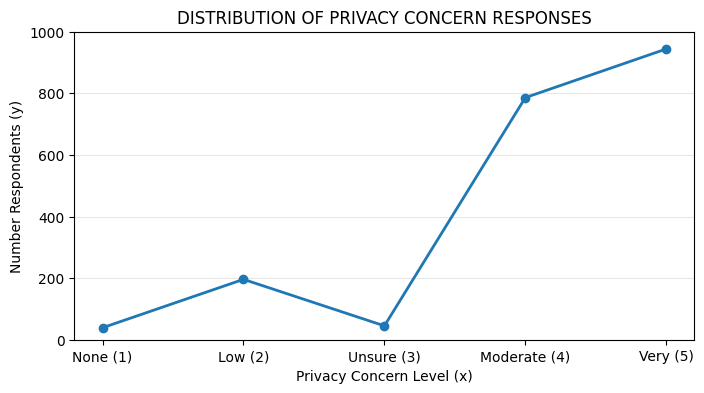

In [46]:
priv_counts = (
    df_ints["gen_priv_conc"]
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(8,4))

plt.plot(
    priv_counts.index,
    priv_counts.values,
    marker="o",
    linewidth=2
)

plt.ylim(0, 1000)
plt.xticks(
    [1,2,3,4,5],
    ["None (1)", "Low (2)", "Unsure (3)", "Moderate (4)", "Very (5)"]
)

plt.xlabel("Privacy Concern Level (x)")
plt.ylabel("Number Respondents (y)")
plt.title("DISTRIBUTION OF PRIVACY CONCERN RESPONSES")

plt.grid(axis="y", alpha=0.3)
plt.show()

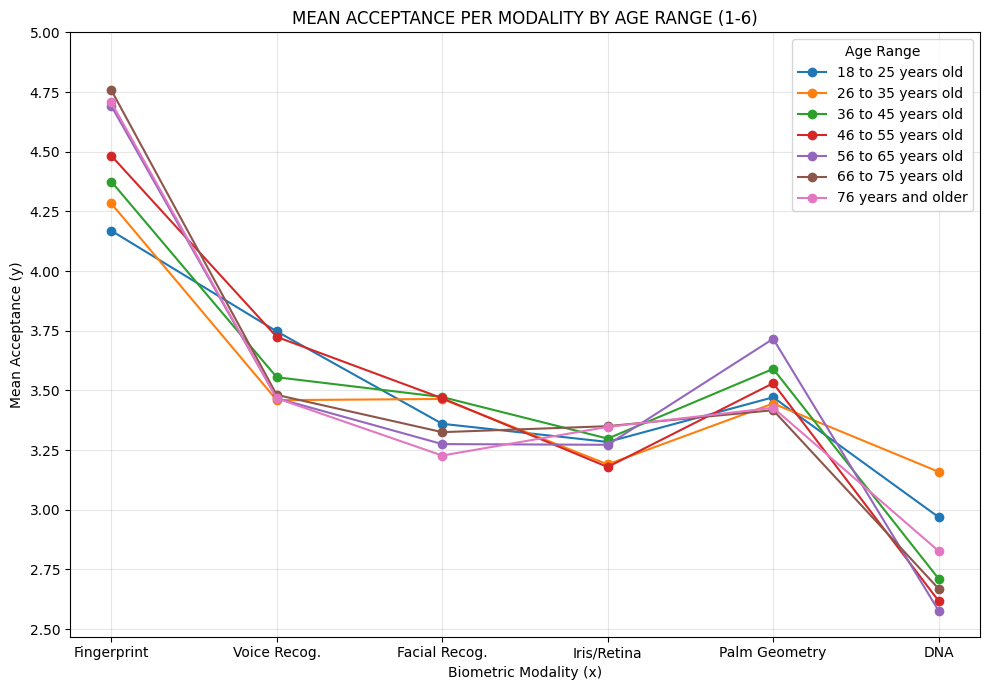

In [47]:
# mean acpt by age line plot
mean_acpt_byage.T.plot(
    marker="o",
    figsize=(10,7)
)

plt.yticks([2.5, 2.75, 3.0, 3.25, 3.5, 3.75, 4.0, 4.25, 4.5, 4.75, 5.0])

plt.xlabel("Biometric Modality (x)")
plt.ylabel("Mean Acceptance (y)")
plt.title("MEAN ACCEPTANCE PER MODALITY BY AGE RANGE (1-6)")

plt.legend(title="Age Range", loc="upper right")
plt.grid(axis="both", alpha=0.3)

plt.tight_layout()
plt.show()

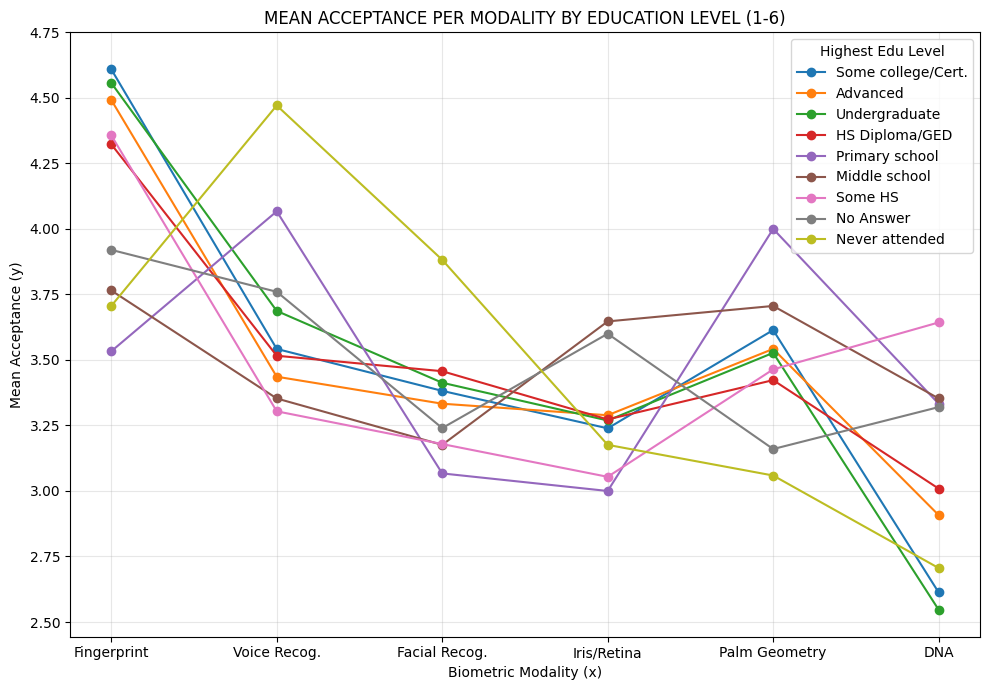

In [48]:
# mean acpt by edu line plot
mean_acpt_byedu.T.plot(
    marker="o",
    figsize=(10,7)
)

plt.yticks([2.5, 2.75, 3.0, 3.25, 3.5, 3.75, 4.0, 4.25, 4.5, 4.75])

plt.xlabel("Biometric Modality (x)")
plt.ylabel("Mean Acceptance (y)")
plt.title("MEAN ACCEPTANCE PER MODALITY BY EDUCATION LEVEL (1-6)")

plt.legend(title="Highest Edu Level", loc="upper right")
plt.grid(axis="both", alpha=0.3)

plt.tight_layout()
plt.show()

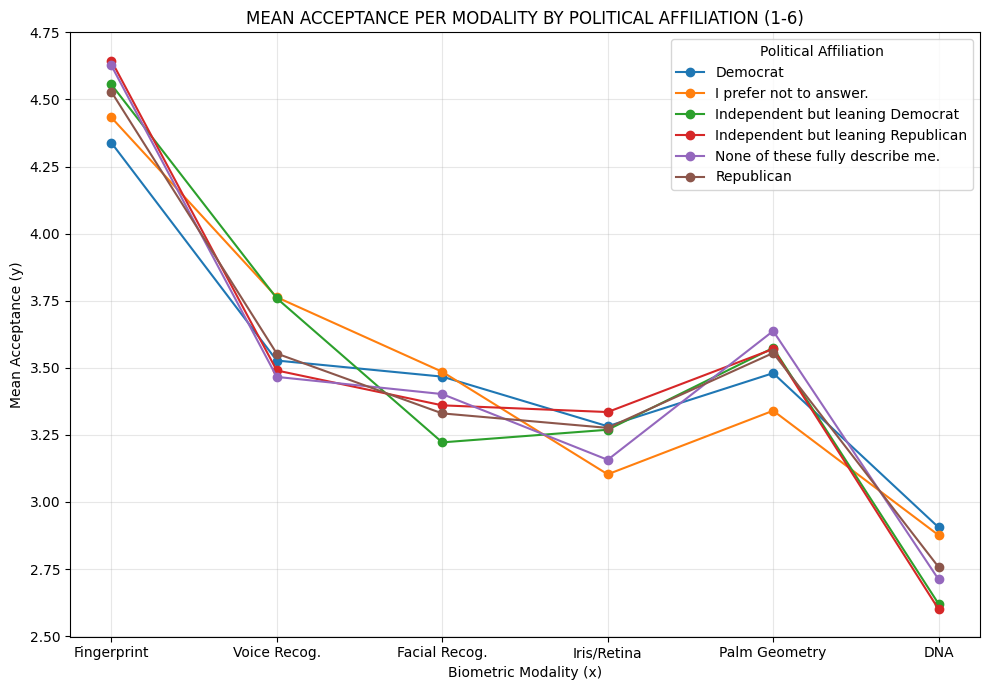

In [49]:
# mean acpt by pol line plot
mean_acpt_bypol.T.plot(
    marker="o",
    figsize=(10,7)
)

plt.grid(axis="both", alpha=0.3)
plt.yticks([2.5, 2.75, 3.0, 3.25, 3.5, 3.75, 4.0, 4.25, 4.5, 4.75])

plt.xlabel("Biometric Modality (x)")
plt.ylabel("Mean Acceptance (y)")
plt.title("MEAN ACCEPTANCE PER MODALITY BY POLITICAL AFFILIATION (1-6)")

plt.legend(
    title="Political Affiliation",
    loc="upper right"
)

plt.tight_layout()
plt.show()

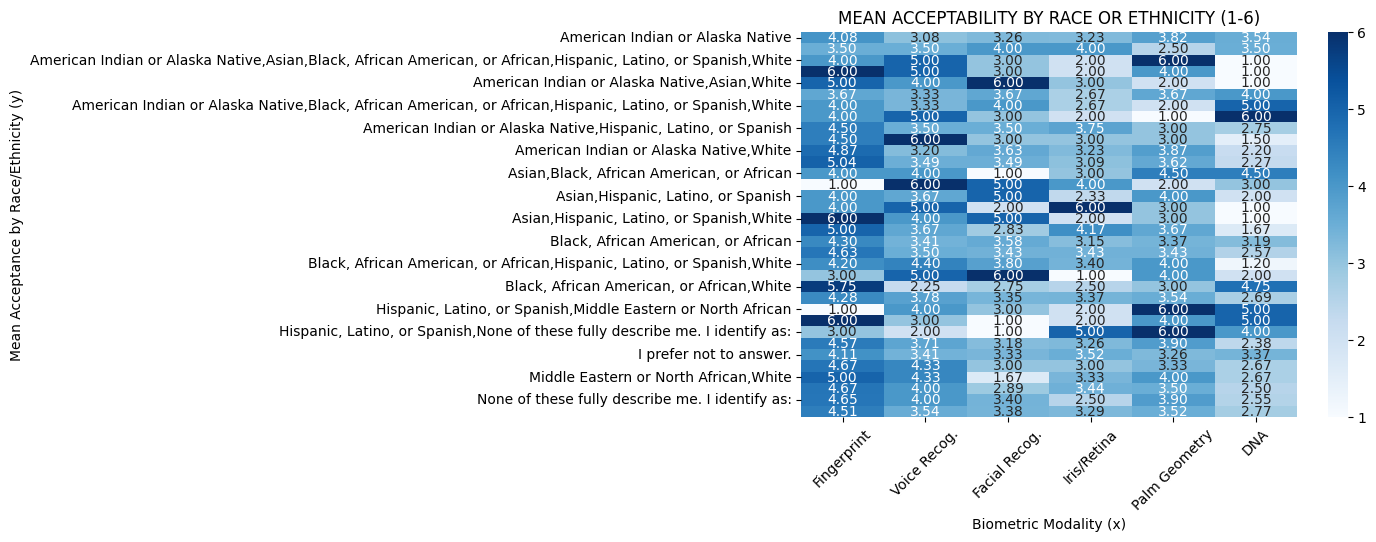

In [50]:
# mean acpt by race heatmap
plt.figure(figsize=(8,5))

sns.heatmap(
    mean_acpt_byrace,
    annot=True,
    cmap="Blues",
    fmt=".2f"
)

plt.xticks(rotation=45)

plt.xlabel("Biometric Modality (x)")
plt.ylabel("Mean Acceptance by Race/Ethnicity (y)")
plt.title("MEAN ACCEPTABILITY BY RACE OR ETHNICITY (1-6)")

plt.show()

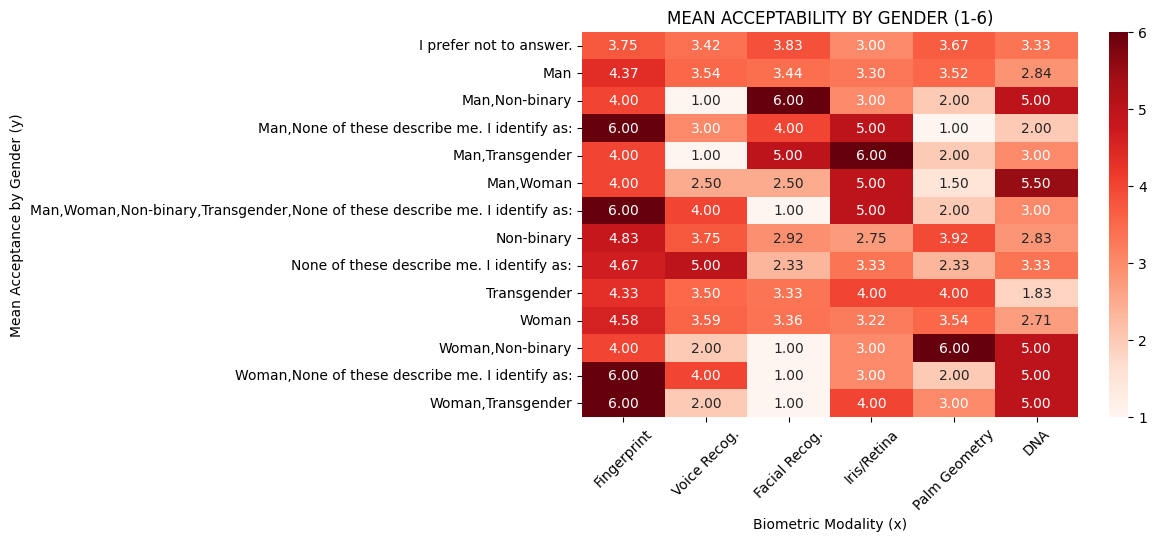

In [51]:
# mean acpt by gender heatmap
plt.figure(figsize=(8,5))

sns.heatmap(
    mean_acpt_bygender,
    annot=True,
    cmap="Reds",
    fmt=".2f"
)

plt.xticks(rotation=45)

plt.xlabel("Biometric Modality (x)")
plt.ylabel("Mean Acceptance by Gender (y)")
plt.title("MEAN ACCEPTABILITY BY GENDER (1-6)")

plt.show()

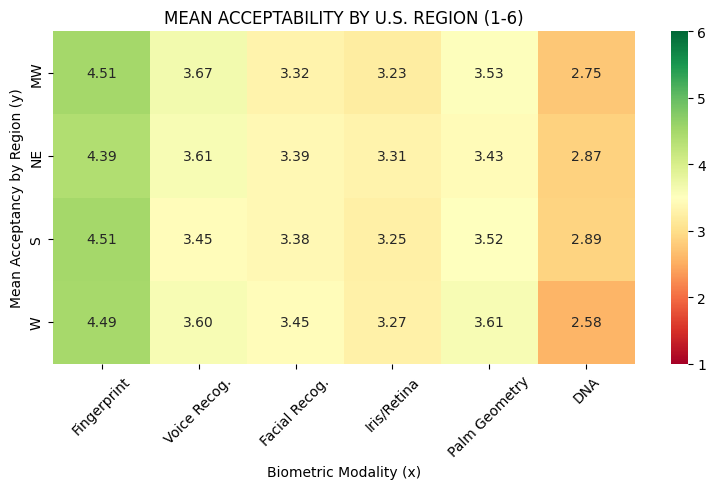

In [52]:
# mean acpt by geo region heatmap
plt.figure(figsize=(8,5))

sns.heatmap(
    mean_acpt_byregion,
    annot=True,
    fmt=".2f",
    cmap="RdYlGn",
    vmin=1,
    vmax=6
)

plt.xticks(rotation=45)

plt.xlabel("Biometric Modality (x)")
plt.ylabel("Mean Acceptancy by Region (y)")
plt.title("MEAN ACCEPTABILITY BY U.S. REGION (1-6)")

plt.tight_layout()
plt.show()

In [53]:
### CORRELATION TESTING ###

In [54]:
modalities = [
    ("finger", "Fingerprint"),
    ("voice", "Voice Recog"),
    ("face", "Facial Recog"),
    ("eye", "Iris/Retina"),
    ("palm", "Palm Geometry"),
    ("dna", "DNA")
]

In [55]:
# spearman test exp per modality vs acpt per modality
exp_results = []

for var_name, full_name in modalities:
    rho, p = spearmanr(
        df_ints[f"exp_{var_name}"],
        df_ints[f"acpt_type_{var_name}"],
        nan_policy="omit"
    )
    exp_results.append([
        full_name,
        round(rho, 3),
        round(p, 4)
    ])

corr_exp_acpt = pd.DataFrame(
    exp_results,
    columns=["Biometric Type", "| Experience rho", "| p-value"]
)

display(corr_exp_acpt)

,Biometric Type,| Experience rho,| p-value
0,Fingerprint,0.164,0.0000
1,Voice Recog,0.101,0.0000
2,Facial Recog,0.124,0.0000
3,Iris/Retina,0.119,0.0000
4,Palm Geometry,0.015,0.5149
5,DNA,0.229,0.0000


In [56]:
# spearman test privacy concern vs acpt per modality
priv_results = []

for var_name, full_name in modalwities:
  rho, p = spearmanr(
      df_ints["gen_priv_conc"],
      df_ints[f"acpt_type_{var_name}"],
      nan_policy="omit"
  )
  priv_results.append([
        full_name,
        round(rho, 3),
        round(p, 4)
    ])

corr_priv_acpt = pd.DataFrame(
    priv_results,
    columns=["Modality", "| Privacy Concern rho", "| p-value"]
)

display(corr_priv_acpt)

NameError: name 'modalwities' is not defined

In [ ]:
# spearman results dual plot
compare_corr = pd.DataFrame({
    "Modality": ["Fingerprint", "Voice Recog", "Facial Recog", "Iris/Retina", "Palm Geometry", "DNA"],
    "Experience Rho": [0.164, 0.101, 0.124, 0.119, 0.015, 0.229],
    "Privacy Rho": [-0.033, 0.044, 0.023, -0.035, 0.021, -0.010]
})

# line 1
plt.plot(
    compare_corr["Modality"],
    compare_corr["Experience Rho"],
    marker="s",
    linewidth=1,
    label="Modality Experience & User Acceptance"
)

# line 2
plt.plot(
    compare_corr["Modality"],
    compare_corr["Privacy Rho"],
    marker="o",
    linewidth=2,
    label="Privacy Concern & User Acceptance"
)

plt.axhline(y=0, color="black", linestyle="--", alpha=0.5)
plt.xticks(rotation=45)
plt.ylim([-0.05, 0.3])

plt.ylabel("Spearman Correlation (p)")
plt.xlabel("Biometric Modality (x)")
plt.title("COMPARISON OF CORRELATION SPEARMAN TESTS")

plt.legend()
plt.grid(axis="both", alpha=0.3)

plt.tight_layout()
plt.show()